# Real diffraction to a complete periodic electron-density contrast


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`hkl`，shape `(1, 4508, 3)`，dtype `<i4`：Integer Miller coordinates in the measured lattice basis, dimensionless; final axis h, k, l.；`intensity`，shape `(1, 4508)`，dtype `<f8`：Signed integrated reflection intensity in relative intensity units; measurement order matches hkl. The complete observed RMS is one.；`sigma_intensity`，shape `(1, 4508)`，dtype `<f8`：Reported positive standard uncertainty of each signed intensity, in the same relative intensity units.。未知量为完整周期单胞相对电子密度对比图。

获取模型：傅里叶结构因子的模平方给出4508个实测反射强度，未测零频需规范约定。

如何恢复：src.solvers.reconstruct/physics_model.charge_flip_update：随机相位与charge-flipping、对称原点选择。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3反射数据；6主反演/参考；8初始化、预算和阈值；10随机相位负对照、物理一致性与迭代快照。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。相对密度而非绝对电子数；实测Fo²原始全局比例曾与精修模型关联，须保留现有数据来源限定。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
Recover a full three-dimensional periodic relative density from4508 measured
single-crystal intensities without their phases. The output is a zero-mean
contrast map, not absolute electron count or fitted atomic coordinates.
The data do not fix a global periodic origin or spatial inversion. No independent
experimental density truth is available; original-method agreement is numerical
validation. All165888 voxels and all signed measurements remain evaluated.


In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,subprocess,importlib.util
import numpy as np
import scipy,matplotlib
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,initialize_structure_factors
from src.physics_model import structure_factors,intensity_relative_error
from src.solvers import reconstruct
from src import visualization as viz
spec=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
FIG=Path(os.environ['IMAGING_FIGURE_DIR']);FIG.mkdir(parents=True,exist_ok=True)
viz.style();start=time.perf_counter()
data=load_observations(ROOT/'data/raw_data.npz')
environment={'python':sys.version,'executable':sys.executable,'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend()}
print(environment)
def show(bundle,name):
    fig,numeric=bundle;viz.export(fig,name,FIG,numeric);plt.show();plt.close(fig)


{'python': '3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]', 'executable': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe', 'numpy': '2.4.6', 'scipy': '1.17.1', 'matplotlib': '3.11.1', 'backend': 'module://matplotlib_inline.backend_inline'}


## 2. Data
These are existing measured Fo-squared intensities, not synthetic diffraction.
The original global scale was fitted to a structural model; dividing **all**
Fo-squared and uncertainties by measured RMS removes that unavailable absolute
gain. No calculated amplitudes, model phases, atomic coordinates or F000 enter
the input. All136 negative measurements are retained. The selected source method
uses unweighted amplitude projection; reported uncertainties remain visible.
P21 is the author's actual identified symmetry; P21/c in preliminary teaching
metadata is not silently imposed. The complete cell has a=15.8489,b=5.5008,
c=23.1175 angstrom and beta=96.916 degrees.


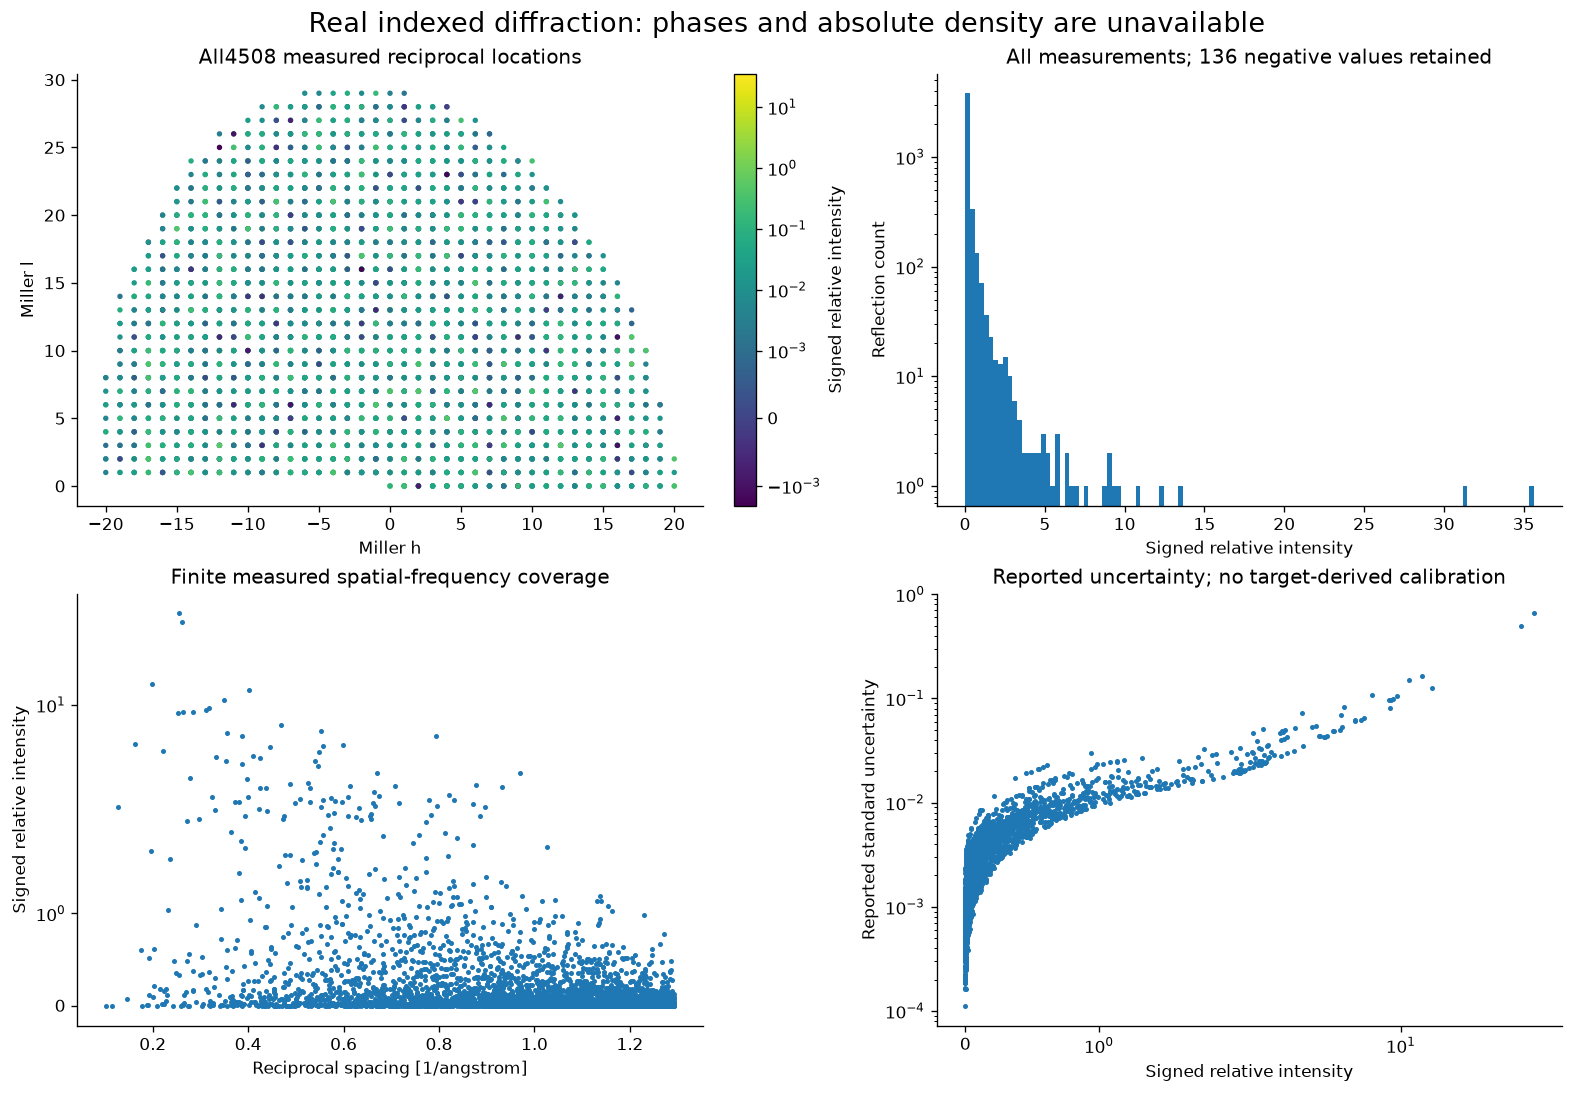

In [2]:
show(viz.plot_observations(data),'figure01_real_diffraction')

## 3. Physics
For grid index $j$, fractional position $u_j$ and Miller vector $h$, the local
acquisition model is

$$F_h=\frac{10}{N}\sum_j\rho_j\exp(2\pi i h\cdot u_j),\qquad I_h=|F_h|^2+\eta_h.$$

Here $N=72\times24\times96$, $\rho_j$ is the real relative density contrast,
$i^2=-1$, $F_h$ is complex scattering amplitude and $\eta_h$ is noise. The
factor ten fixes output scale; no gain is optimized. Friedel partners are
conjugates. The two P21 rotations and half-b screw translation expand measured
moduli. Zero direct-beam amplitude gives a zero-mean contrast. Cartesian
coordinates use the monoclinic lattice basis, rather than treating fractional
axes as orthogonal lengths. Periodic translation and whole-map spatial inversion
preserve every measured intensity.


## 4. Method
Actively initialize missing phases, expand measured amplitudes, then execute all
selected200 source updates. With $r$ the real FFT density and $\sigma$ its
population standard deviation, reverse signs where $r<0.1\sigma$ or
$r>30\sigma$. Inverse-transform the modified map, preserve its phases, and
replace moduli by observed $\sqrt{\max(I,0)}$. Exact zero temporary factors
receive the source guard before phase division. This is custom dual-space
feasibility iteration, not a guaranteed descent algorithm. Its source diagnostic
Rcf is distinct from the all-signed-intensity physical residual. The5% early
stop remains active; the actual200-step budget need not converge. Apply the
original heuristic origin roll and divide by ten.

Original NumPy1.26 and local code on that backend match every state bitwise.
Long trajectories differ in NumPy2.4 because of roundoff. The qualified author's
NumPy2.4 run uses a one-line postprocessing reshape API compatibility repair;
its unchanged inverse math matches this fresh run bitwise. The old unmodified
baseline and criteria frozen before extraction remain preserved. Modern fixtures
were captured independently **after** discovering this backend issue and are
explicitly not pre-extraction evidence.


Independent Judge native exit: 0 
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9989629082253738,
    "nrmse": 0.001758786221731934,
    "intensity_relative_l2": 0.00010239649895416404,
    "mean_relative": 5.5514425609748885e-18
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.014489186542210463
    },
    "intensity_relative_l2": {
      "comparison": "<=",
      "boundary": 0.00011263614884958044
    },
    "mean_relative": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": [],
  "alignment": {
    "periodic_shift_voxels": [
      0.0048995253914495395,
      5.016346148158037e-05,
      0.0027140056593199483
    ],
    "spatial_inversion": false
  }
}


Actual updates/runtime: 200 6.4986091000027955 alignment: [4.89952539e-03 5.01634615e-05 2.71400566e-03] False


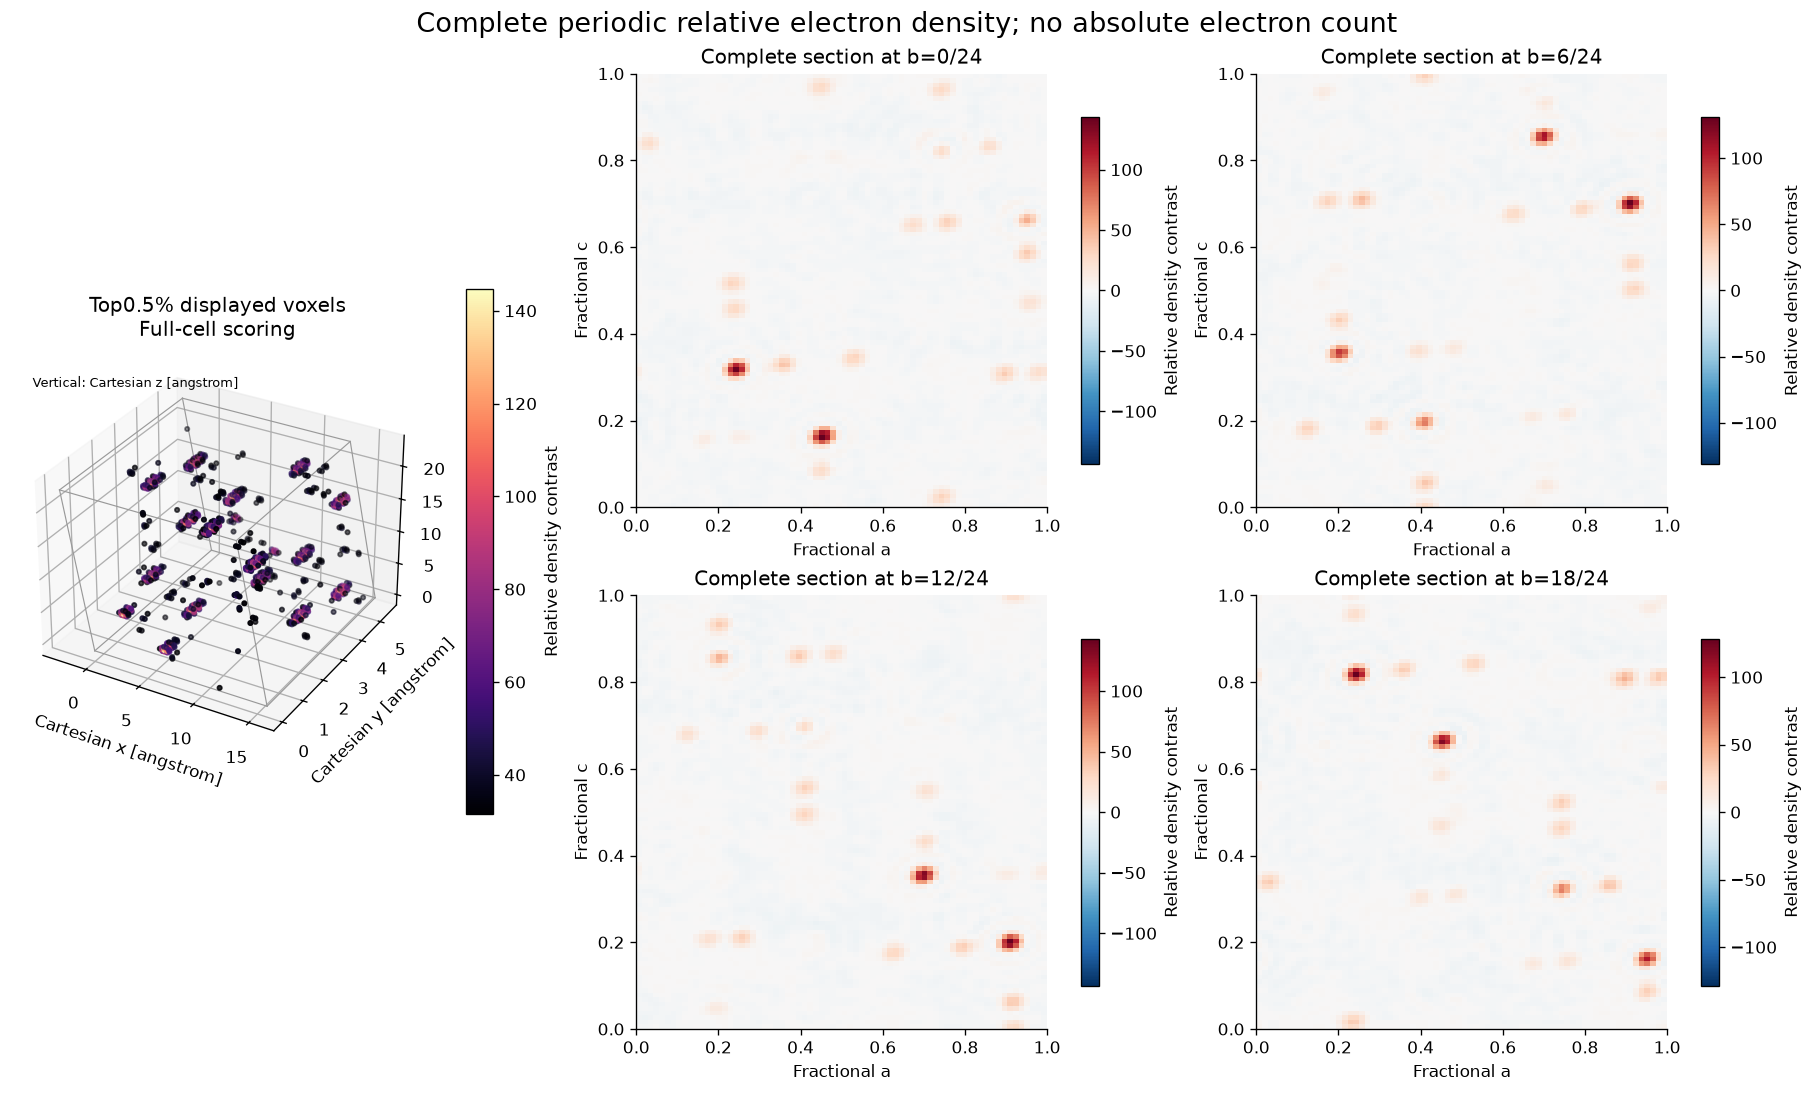

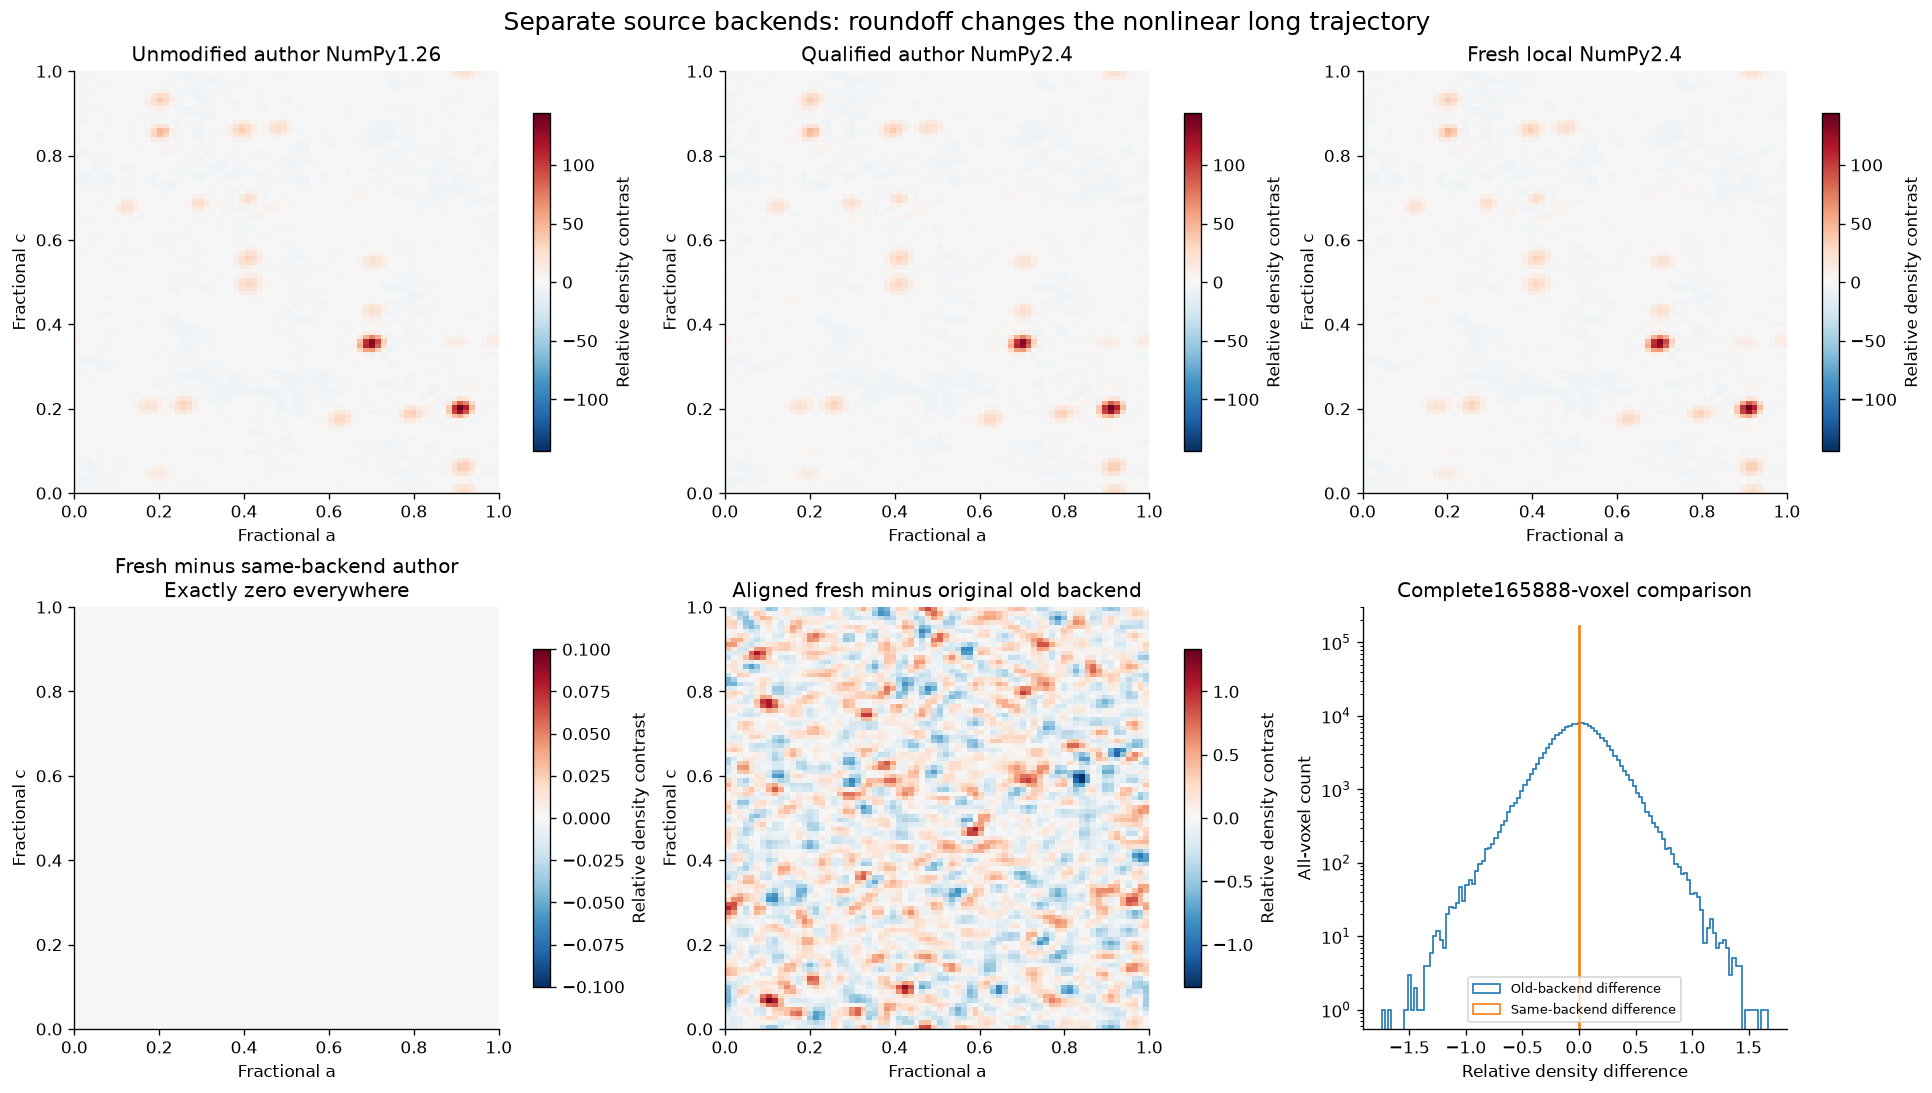

In [3]:
primary=reconstruct(data)
prediction=ROOT/'output/reconstruction.npz';prediction.parent.mkdir(exist_ok=True)
np.savez_compressed(prediction,reconstruction=primary['reconstruction'][None])
process=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(prediction),'--report',str(ROOT/'output/judge_report.json')],cwd=ROOT,capture_output=True,text=True)
print('Independent Judge native exit:',process.returncode,process.stderr)
assert process.returncode==0
report=json.loads((ROOT/'output/judge_report.json').read_text());print(json.dumps(report,indent=2))
old=np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False)['reconstruction'][0]
modern=np.load(ROOT/'test/fixtures/upstream_modern_stages.npz',allow_pickle=False)['reconstruction']
assert np.array_equal(primary['reconstruction'],modern)
source=dict(np.load(ROOT/'notebooks/reference_outputs/source_comparisons.npz',allow_pickle=False))
old_stages=dict(np.load(ROOT/'test/fixtures/upstream_stages.npz',allow_pickle=False))
aligned,shift,inverted=judge.align_periodic(primary['reconstruction'],old)
print('Actual updates/runtime:',primary['iterations'],primary['runtime_seconds'],'alignment:',shift,inverted)
show(viz.plot_density(primary['reconstruction']),'figure02_full_cell_density')
show(viz.plot_parity(primary['reconstruction'],old,modern,aligned),'figure03_backend_and_original_parity')


## 5. Results and actual comparisons
The primary result above was computed from the public observations. The following
full-volume controls are also freshly reconstructed: two independent phase seeds,
shorter20-step budget, and upper thresholds20 and50. None is filled from a cache.
Original source20%-GUI cancellation, independent original seeds and original
old-backend history are loaded only as labeled source comparisons. The GUI20%
run actually lasts24 updates; it is not mislabeled as a20-update run.


seed23 actual steps 200 seconds 6.640080400000443


seed24 actual steps 200 seconds 6.486663799994858


budget20 actual steps 20 seconds 1.0389502000034554


upper20 actual steps 200 seconds 6.4496043999970425


upper50 actual steps 200 seconds 6.246909699999378


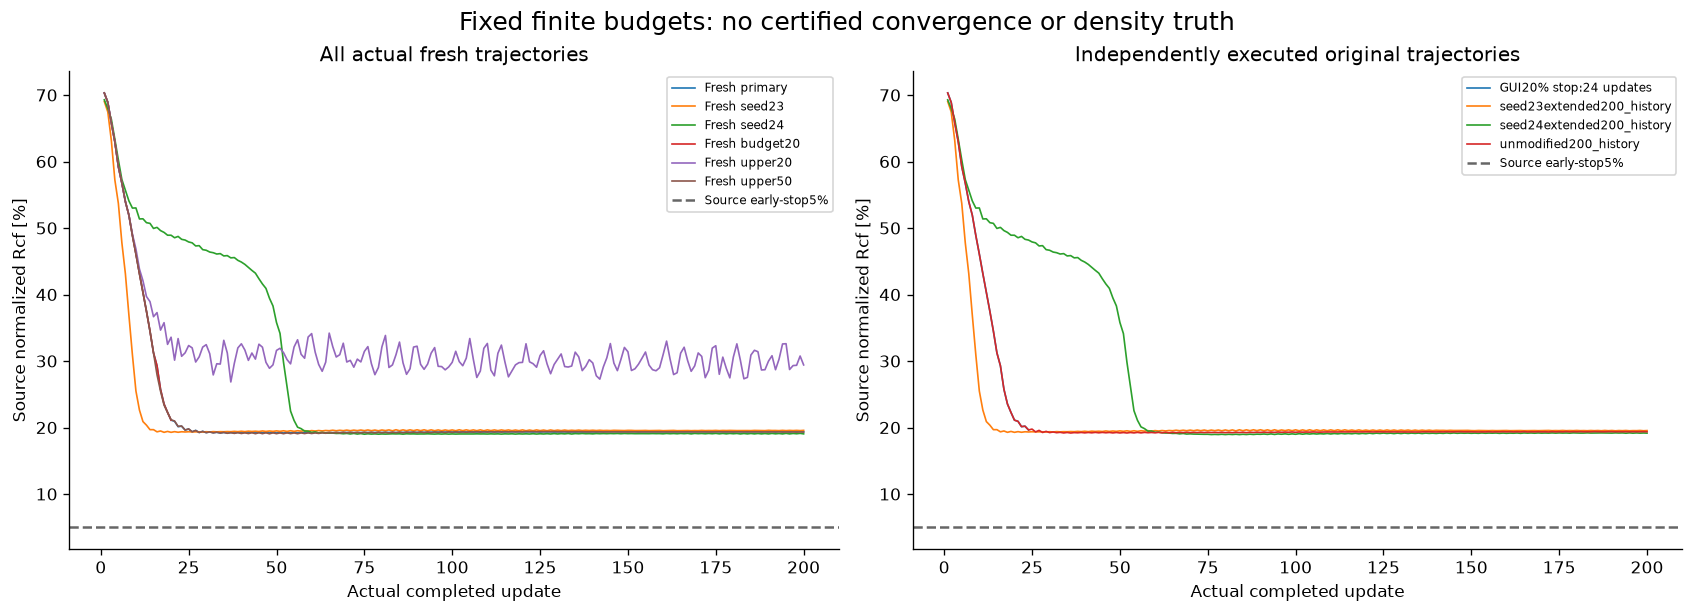

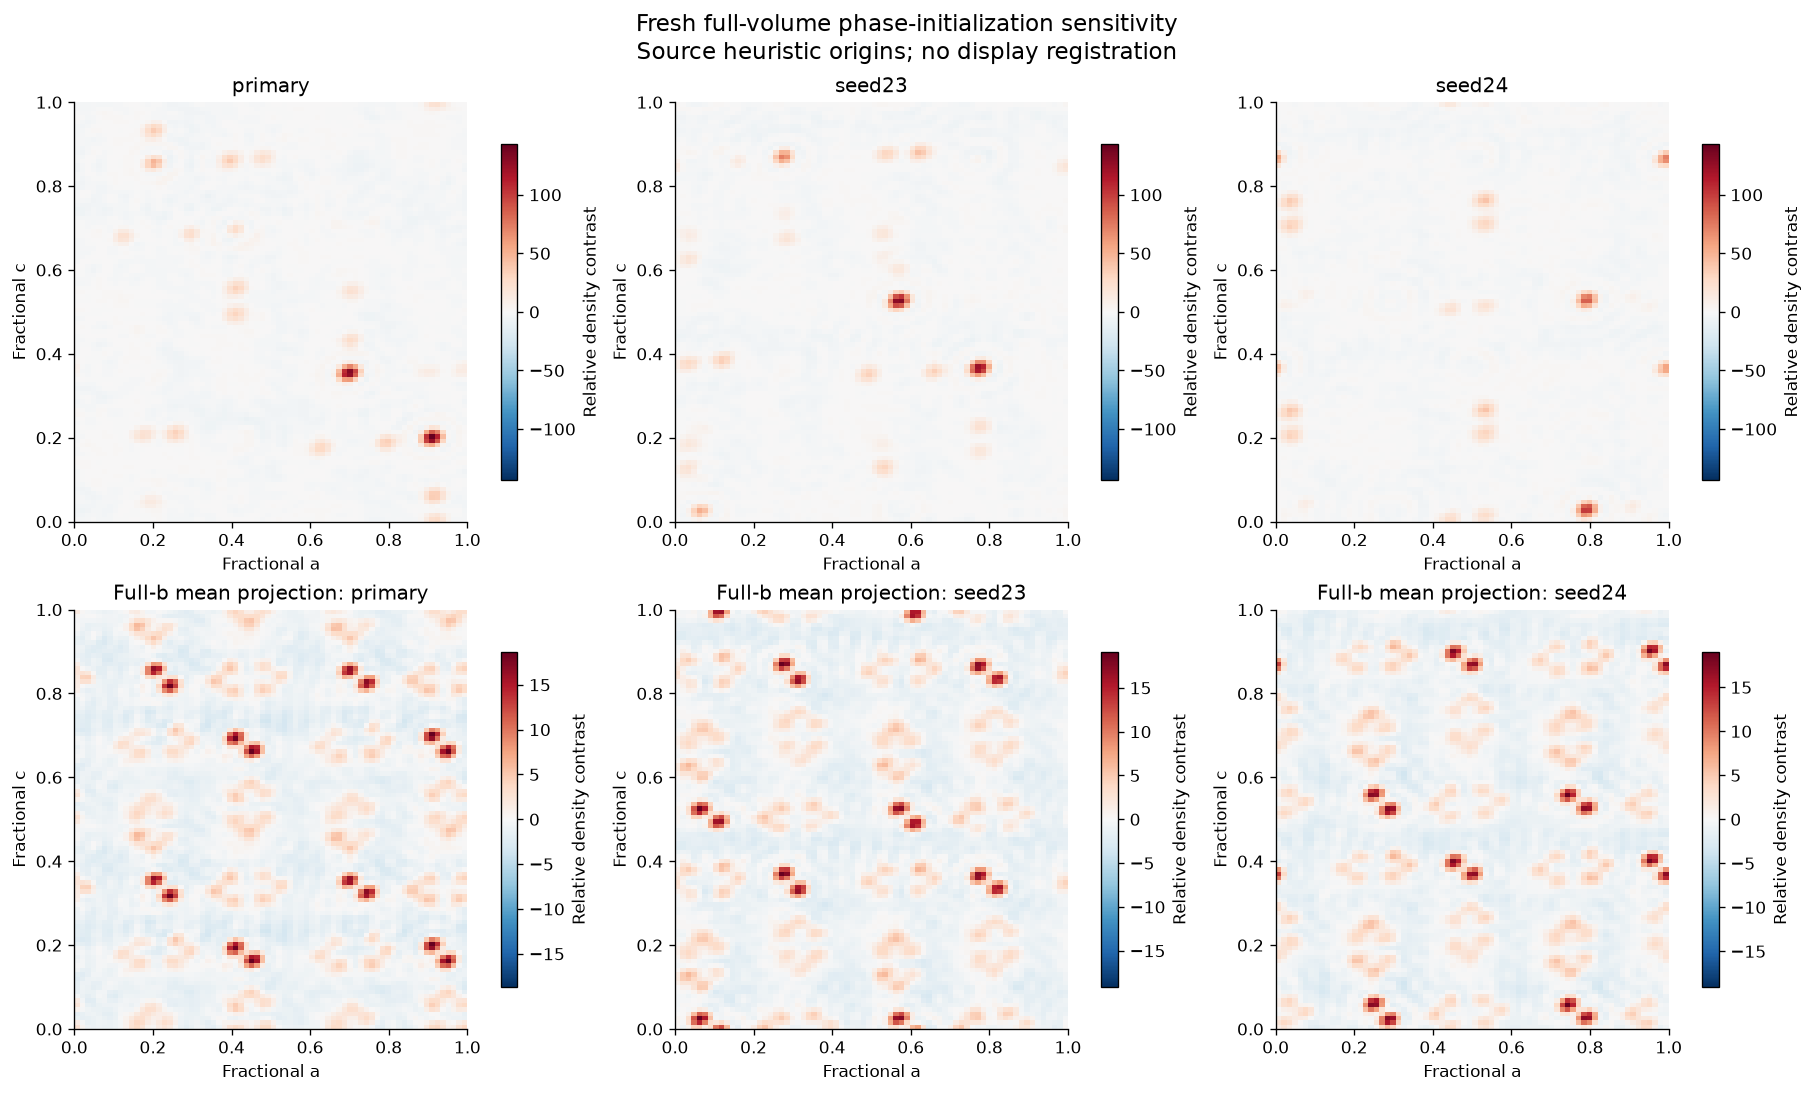

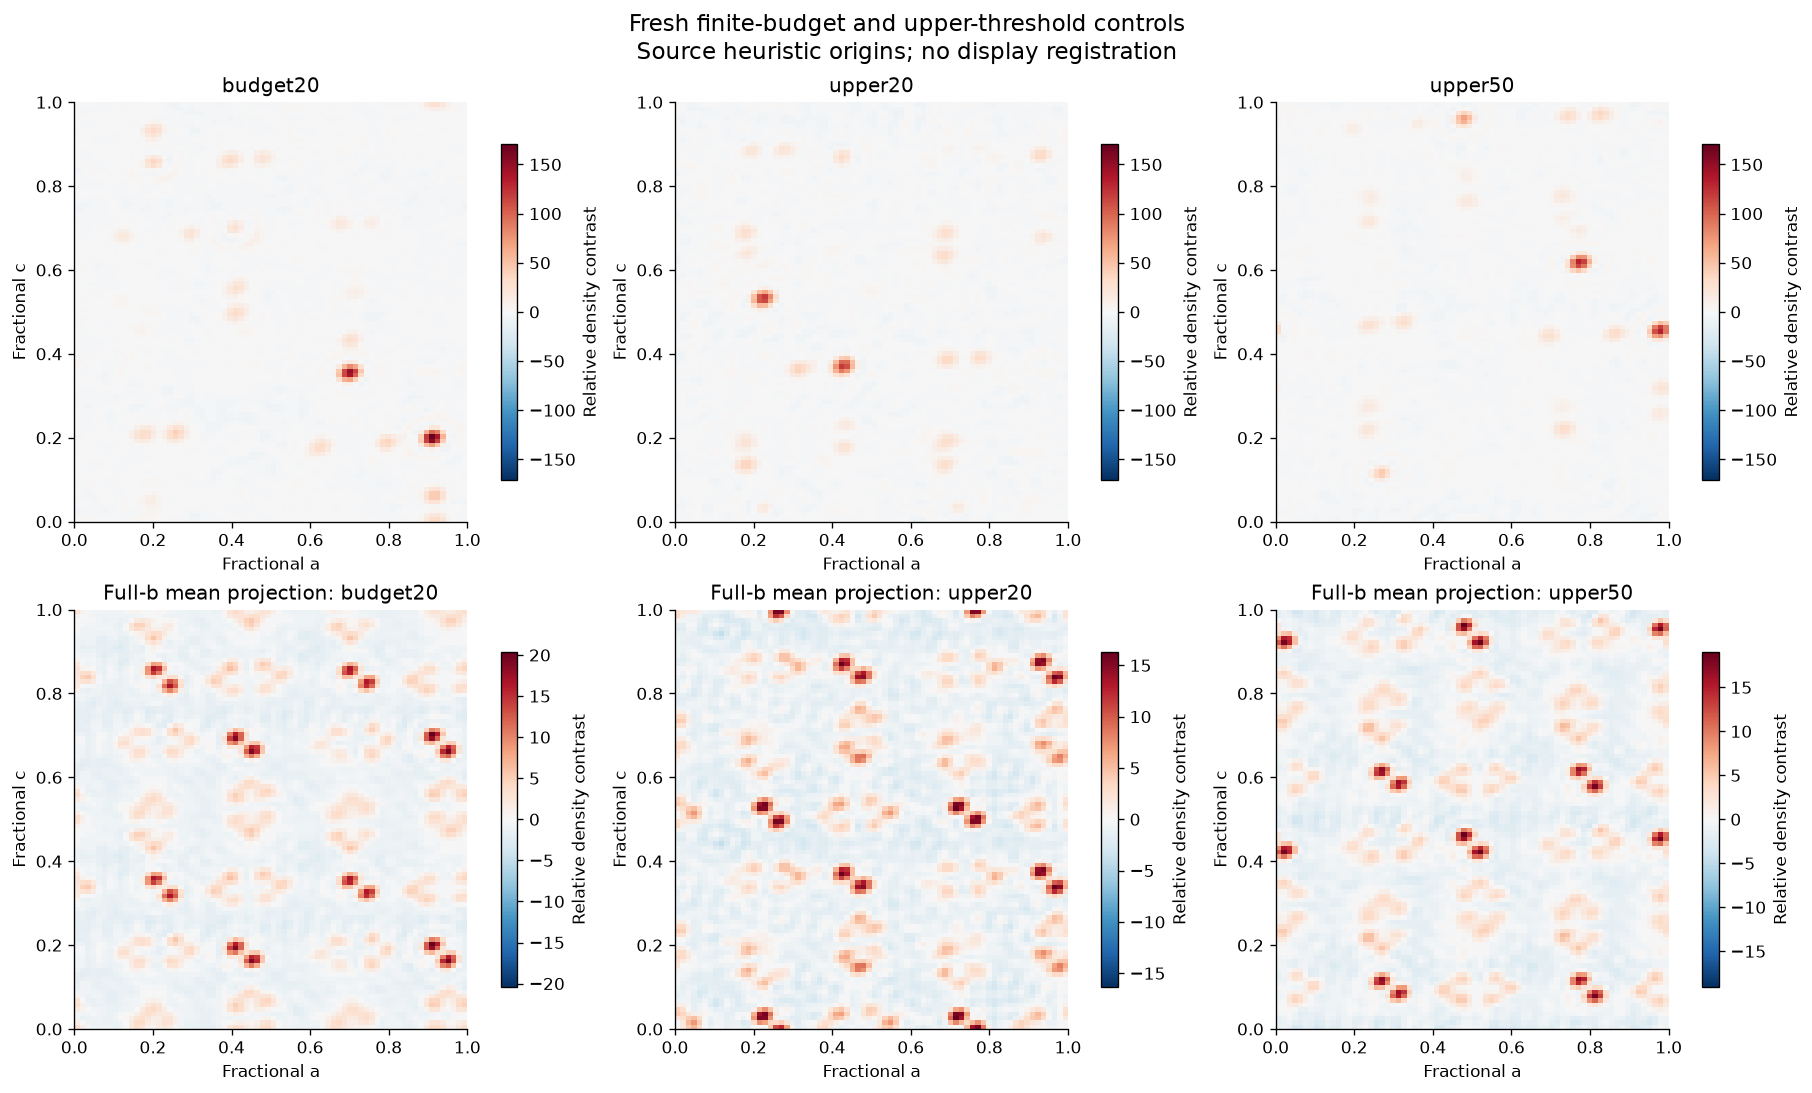

In [4]:
runs={'primary':primary}
for name,options in [('seed23',{'seed':20261023}),('seed24',{'seed':20261024}),('budget20',{'iterations':20}),('upper20',{'k_max':20.}),('upper50',{'k_max':50.})]:
    runs[name]=reconstruct(data,**options)
    print(name,'actual steps',runs[name]['iterations'],'seconds',runs[name]['runtime_seconds'])
original_histories={k:v for k,v in source.items() if k.endswith('_history')}
original_histories['unmodified200_history']=old_stages['history']
show(viz.plot_histories(runs,original_histories),'figure04_all_actual_trajectories')
show(viz.plot_controls(runs,['primary','seed23','seed24'],'Fresh full-volume phase-initialization sensitivity'),'figure05_initialization_comparisons')
show(viz.plot_controls(runs,['budget20','upper20','upper50'],'Fresh finite-budget and upper-threshold controls'),'figure06_budget_threshold_comparisons')


A random-phase amplitude-constrained map can fit positive measured moduli
without recovering the density. We compute that poor control directly from
initialization. All negative intensities remain in the physical residual.
Alignment uses whole-map translation/inversion only, with analytic-gradient
multistart refinement and no fitted amplitude gain. These comparisons assess
method agreement and conditional stability, not true crystallographic accuracy.


{
  "primary": {
    "ncc": 0.9989629082253738,
    "nrmse": 0.001758786221731934,
    "all_signed_intensity_l2": 0.00010239649895416404
  },
  "seed23": {
    "ncc": 0.9505036428975289,
    "nrmse": 0.012150414059209405,
    "all_signed_intensity_l2": 0.00010239649895416404
  },
  "seed24": {
    "ncc": 0.9426336850805748,
    "nrmse": 0.013080758755138191,
    "all_signed_intensity_l2": 0.00010239649895416404
  },
  "random phases": {
    "ncc": 0.12136233819651374,
    "nrmse": 0.051192856960672946,
    "all_signed_intensity_l2": 0.00010239649895416404
  }
}


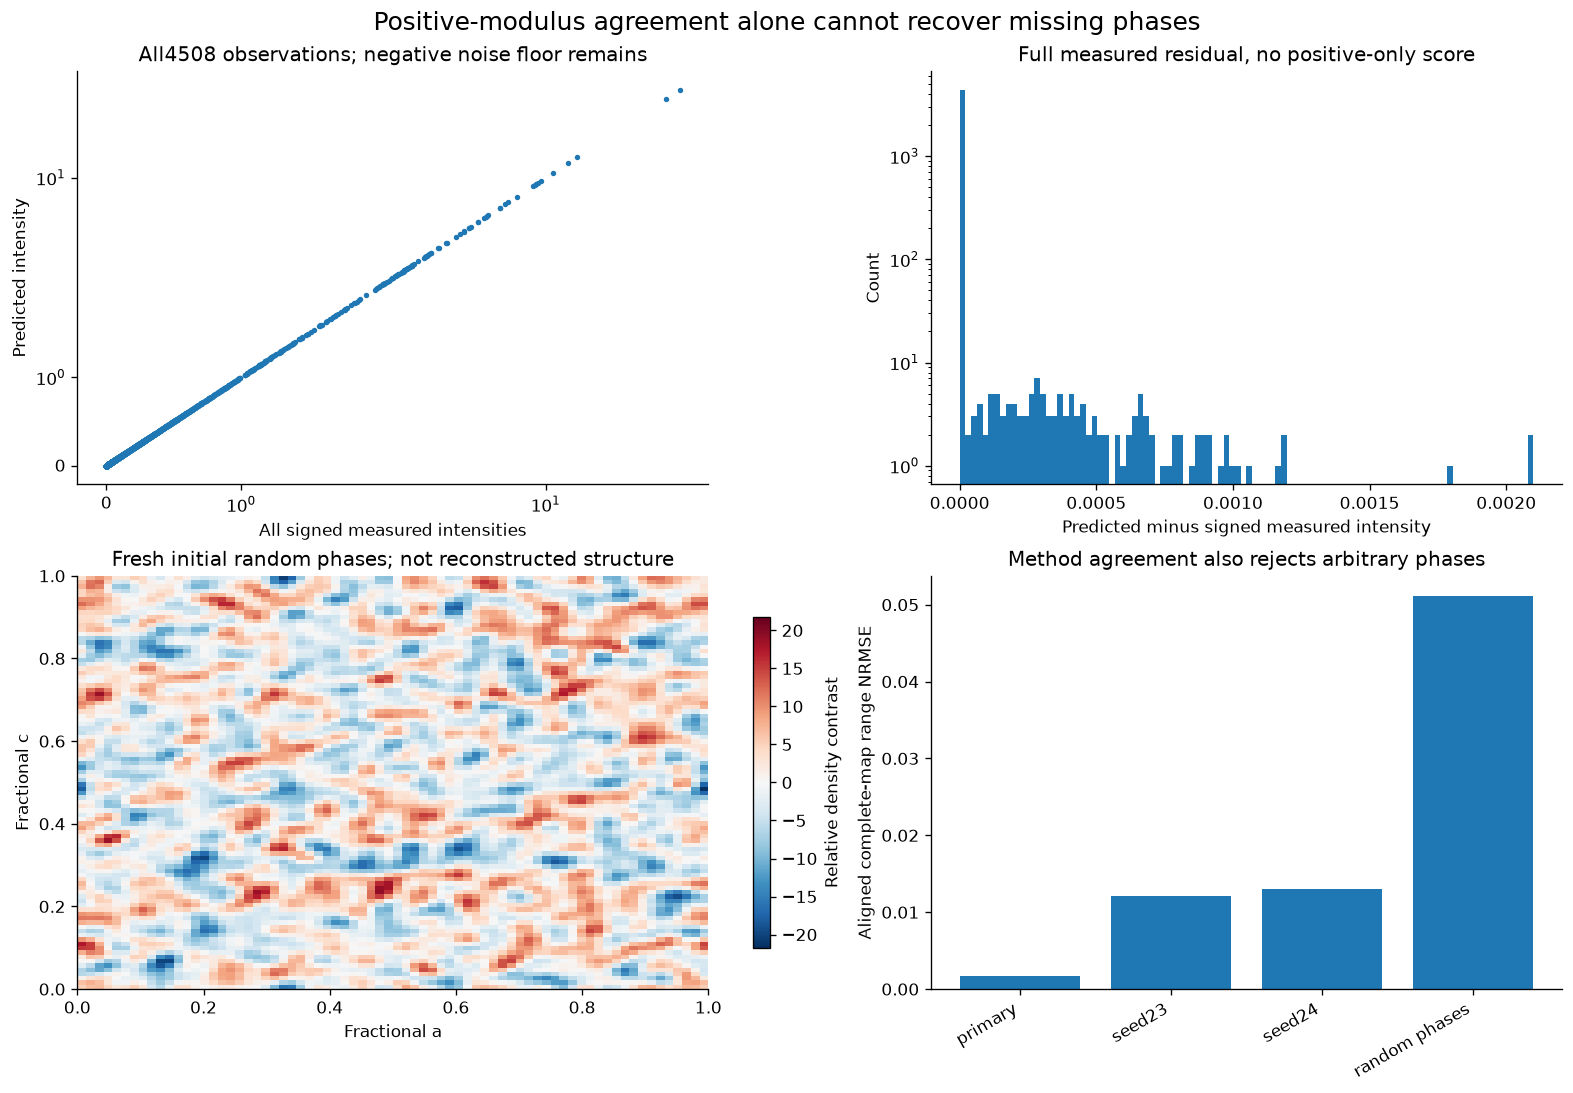

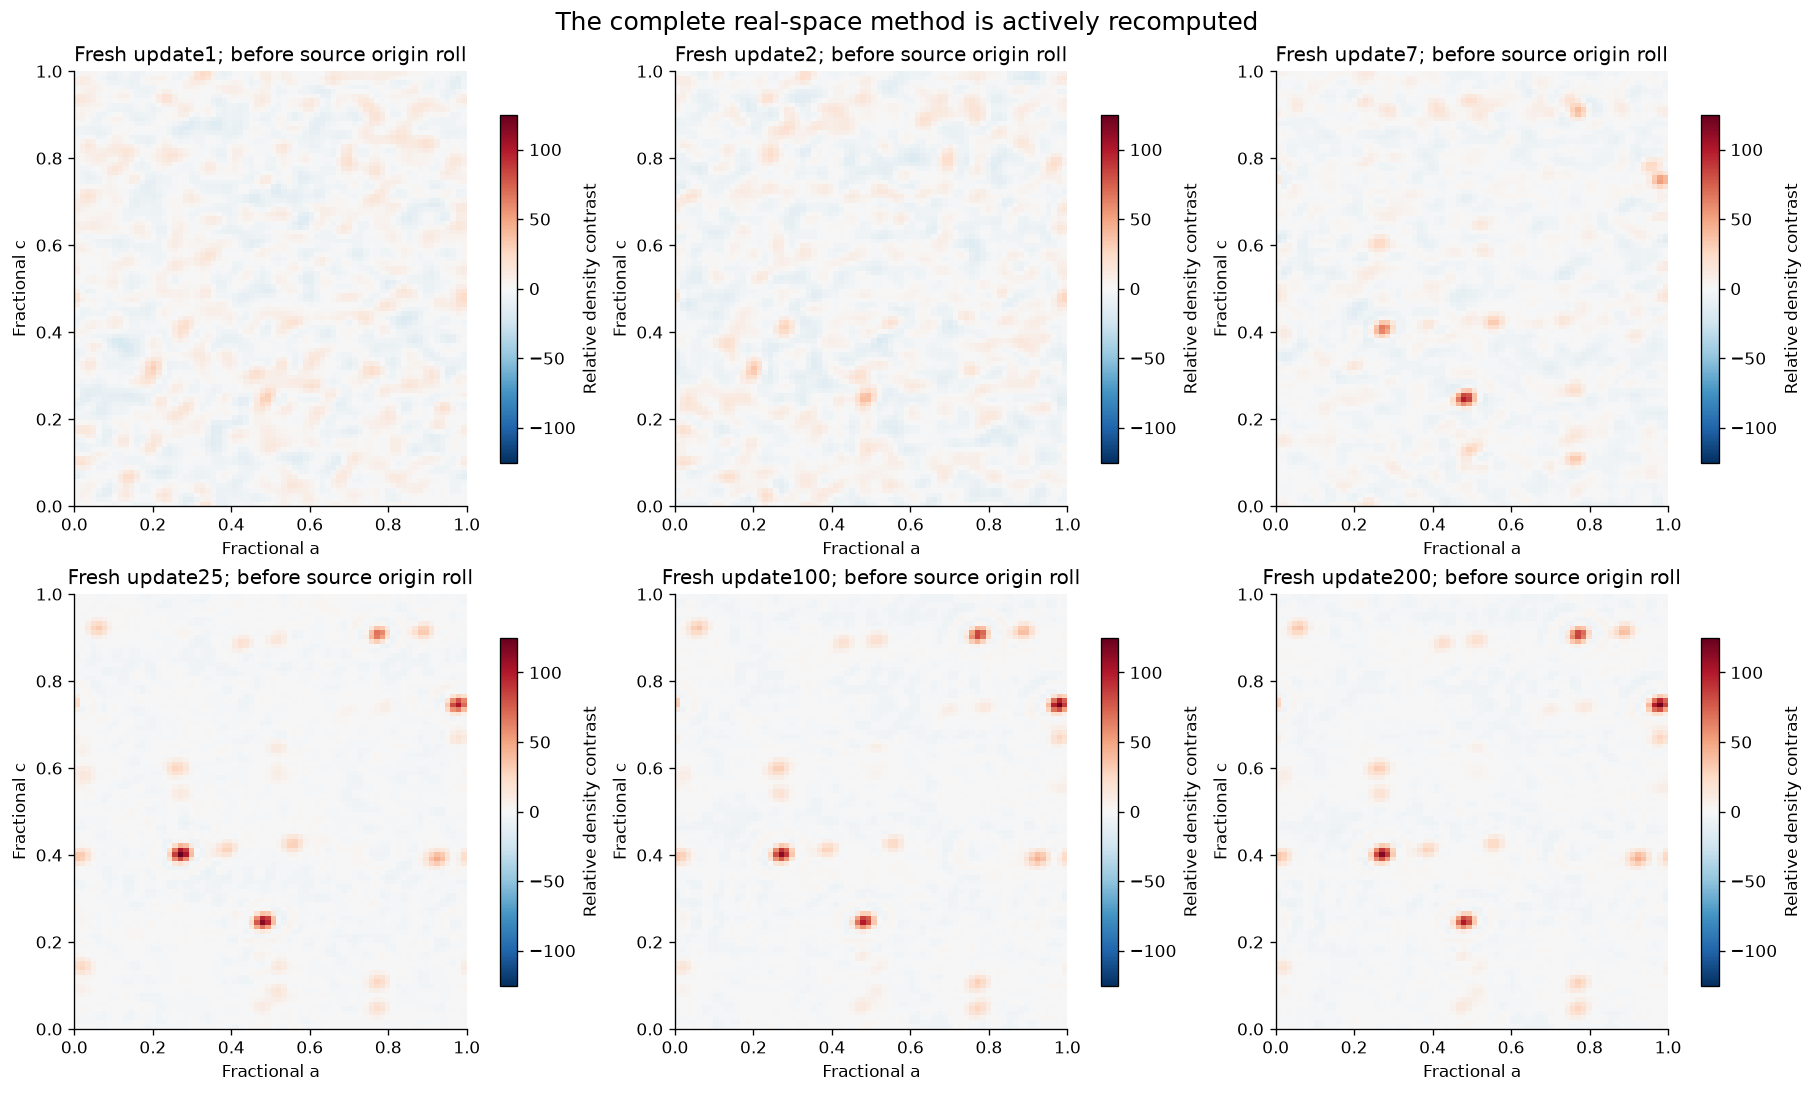

Actual review runtime seconds: 61.54411849999451


In [5]:
initial=initialize_structure_factors(data)
random_density=np.fft.fftn(np.fft.fftshift(initial)).real/10
quality={}
for name,rho in [('primary',primary['reconstruction']),('seed23',runs['seed23']['reconstruction']),('seed24',runs['seed24']['reconstruction']),('random phases',random_density)]:
    match,_,_=judge.align_periodic(rho,old)
    quality[name]={'ncc':float(np.sum(match*old)/(np.linalg.norm(match)*np.linalg.norm(old))),'nrmse':float(np.sqrt(np.mean((match-old)**2))/np.ptp(old)),'all_signed_intensity_l2':intensity_relative_error(structure_factors(rho,data['hkl']),data['intensity'])}
print(json.dumps(quality,indent=2))
show(viz.plot_consistency(data,runs,random_density,quality),'figure07_physical_consistency_and_poor_control')
show(viz.plot_snapshots(primary),'figure08_fresh_update_snapshots')
metadata={'runtime_seconds':time.perf_counter()-start,'primary_runtime_seconds':primary['runtime_seconds'],'environment':environment,'judge':report,'quality':quality,'raw_sha256':hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest(),'source_roles':{'old':'Unmodified independent NumPy1.26 original, method reference not truth','modern':'Independent qualified NumPy2.4 source captured after backend diagnosis','fresh':'Active local full-volume reconstruction and five full-volume controls'}}
(FIG/'experiment_metrics.json').write_text(json.dumps(metadata,indent=2,allow_nan=False),encoding='utf8')
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_results.npz',reconstruction=primary['reconstruction'],history=primary['history'],**{name:r['reconstruction'] for name,r in runs.items() if name!='primary'})
(ROOT/'notebooks/reference_outputs/fresh_run.json').write_text(json.dumps(metadata,indent=2,allow_nan=False),encoding='utf8')
print('Actual review runtime seconds:',metadata['runtime_seconds'])


## 6. Conclusion
The active local implementation reconstructs the complete periodic density and
passes independently frozen method-agreement, all-signed-observation and
zero-mean criteria. It matches the qualified same-backend source trajectory
bitwise. Independent analytic geometry and Fourier tests complement that parity.

Missing phases, initial-state dependence, finite budgets, arithmetic sensitivity
and absent absolute scale limit interpretation. A low amplitude residual alone
does not validate density. The original NumPy1.26 reference is not experimental
truth, the source origin heuristic is not a certified origin measurement, and
the observed negative noise values are not discarded. Separate source data
redistribution terms were not identified; this is a local research package.

The2013 GSAS-II paper describes the selected double-threshold method; the2004
charge-flipping precursor differs in direct-beam treatment. Exact source revisions,
original failures, compatibility qualification, hashes and every fixture consumer
are recorded in test/validation.md and the private archive.
